# Notebook 1 — Transformer Training (Regime A)

**Student** Xin Yiing · **Group** CrisisLens (36118)

**Member 3 scope:** contextual Transformer model for 10-class humanitarian tweet classification (HumAID). Owns fine-tuning, class-imbalance treatment, calibration, selective prediction, and the `classify(text)` wrapper.

**This notebook** runs 6 encoder + imbalance-strategy experiments (Regime A), applies the pre-registered go/no-go rule, and reruns the winner with a second seed. Outputs (logits, checkpoints, metrics JSON) feed into Notebook 2 (calibration) and Notebook 3 (cross-event evaluation).

## 1 — Environment Setup

### 1.1 — Install dependencies

In [15]:
# One-time environment setup for Kaggle or fresh venv.
# Uncomment the lines below as needed.

# !pip install -q transformers>=4.40 datasets accelerate
# !pip install -q scikit-learn matplotlib seaborn

### 1.2 — Imports

In [16]:
# Standard library
import os, sys, json, time, gc, re, warnings
from collections import Counter
from pathlib import Path

# Numeric and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F

# HuggingFace
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)
from datasets import load_dataset, DatasetDict, Dataset, load_from_disk

# Evaluation
from sklearn.metrics import (
    f1_score,
    classification_report as clf_report,
    confusion_matrix,
)

# ── Display and warnings ──
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

### 1.3 — Labels and constants

In [17]:
# ── Seeds ──
SEED_PRIMARY   = 42
SEED_SECONDARY = 123

# ── Labels (from EDA, confirmed against HumAID parquet) ──
LABELS = [
    "caution_and_advice",
    "displaced_people_and_evacuations",
    "infrastructure_and_utility_damage",
    "injured_or_dead_people",
    "missing_or_found_people",
    "not_humanitarian",
    "other_relevant_information",
    "requests_or_urgent_needs",
    "rescue_volunteering_or_donation_effort",
    "sympathy_and_support",
]
NUM_LABELS = len(LABELS)
LABEL2ID   = {l: i for i, l in enumerate(LABELS)}
ID2LABEL   = {i: l for i, l in enumerate(LABELS)}

# 3 smallest classes by training count (for go/no-go rule)
SMALLEST_3 = [
    "missing_or_found_people",           # 250 train (0.47%)
    "requests_or_urgent_needs",          # 1833 train (3.4%)
    "displaced_people_and_evacuations",  # 2800 train (5.2%)
]

print(f"{'Labels':<20} {NUM_LABELS}")
print(f"{'Seeds':<20} {SEED_PRIMARY}, {SEED_SECONDARY}")

Labels               10
Seeds                42, 123


### 1.4 — Training hyperparameters and experiment grid

In [18]:
MAX_SEQ_LEN    = 128
BATCH_SIZE     = 32
LEARNING_RATE  = 2e-5
WARMUP_RATIO   = 0.1
WEIGHT_DECAY   = 0.01
NUM_EPOCHS     = 5
FOCAL_GAMMA    = 2.0

EXPERIMENT_GRID = [
    {"run_id": "A1", "encoder": "distilbert-base-uncased",         "imbalance": "plain",          "seed": SEED_PRIMARY},
    {"run_id": "A2", "encoder": "distilbert-base-uncased",         "imbalance": "class_weighted", "seed": SEED_PRIMARY},
    {"run_id": "A3", "encoder": "distilbert-base-uncased",         "imbalance": "focal",          "seed": SEED_PRIMARY},
    {"run_id": "A4", "encoder": "cardiffnlp/twitter-roberta-base", "imbalance": "plain",          "seed": SEED_PRIMARY},
    {"run_id": "A5", "encoder": "cardiffnlp/twitter-roberta-base", "imbalance": "class_weighted", "seed": SEED_PRIMARY},
    {"run_id": "A6", "encoder": "cardiffnlp/twitter-roberta-base", "imbalance": "focal",          "seed": SEED_PRIMARY},
]

print(f"{'Experiments':<20} {len(EXPERIMENT_GRID)}")
print(f"{'Epochs':<20} {NUM_EPOCHS}")
print(f"{'Batch size':<20} {BATCH_SIZE}")
print(f"{'Max seq length':<20} {MAX_SEQ_LEN}")

Experiments          6
Epochs               5
Batch size           32
Max seq length       128


### 1.5 — GPU check, output directories, checkpoint system

In [19]:
# PART 1 step 3 — verify GPU, set up output dirs and checkpoint system

assert torch.cuda.is_available(), "No GPU. Enable GPU in Kaggle sidebar -> Accelerator."

ON_KAGGLE = os.path.exists("/kaggle/working")
BASE      = "/kaggle/working" if ON_KAGGLE else "."

OUTPUT_DIR  = os.path.join(BASE, "outputs")
CKPT_DIR    = os.path.join(OUTPUT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results", "transformer")
PRED_DIR    = os.path.join(OUTPUT_DIR, "predictions", "transformer")
LOGITS_DIR  = os.path.join(OUTPUT_DIR, "logits", "transformer")
DATA_CACHE  = os.path.join(BASE, "data_cache")

for d in [OUTPUT_DIR, CKPT_DIR, RESULTS_DIR, PRED_DIR, LOGITS_DIR, DATA_CACHE]:
    os.makedirs(d, exist_ok=True)


# stage_done — check whether a named stage already completed
def stage_done(name):
    return os.path.exists(os.path.join(OUTPUT_DIR, f".done_{name}"))


# mark_done — write marker file so re-runs skip this stage
def mark_done(name):
    open(os.path.join(OUTPUT_DIR, f".done_{name}"), "w").close()
    print(f"  >> stage '{name}' persisted")


print(f"{'GPU':<20} {torch.cuda.get_device_name(0)}")
print(f"{'VRAM':<20} {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"{'Kaggle':<20} {ON_KAGGLE}")
print(f"{'Output dir':<20} {OUTPUT_DIR}")
print(f"{'Existing stages':<20}", end=" ")
existing = [f.replace(".done_", "") for f in os.listdir(OUTPUT_DIR) if f.startswith(".done_")]
print(existing if existing else "(none)")

GPU                  Tesla T4
VRAM                 15.6 GB
Kaggle               True
Output dir           /kaggle/working/outputs
Existing stages      (none)


## 2 — Data Loading

### 2.1 — Resolve data path

In [20]:
# PART 2 step 1 — portable data path across Kaggle and local

CANDIDATES = [
    "/kaggle/input/humaid-all",          # Kaggle dataset
    os.path.join(BASE, "data", "raw", "humaid"),  # local project
]

DATA_DIR = next((p for p in CANDIDATES if Path(p).exists()), None)

if DATA_DIR is not None:
    print(f"{'DATA_DIR':<20} {DATA_DIR}")
    print(f"{'Source':<20} pre-uploaded parquet files")
else:
    print(f"{'DATA_DIR':<20} (not found, will download from HuggingFace Hub)")
    print(f"{'Candidates tried':<20} {CANDIDATES}")

DATA_DIR             (not found, will download from HuggingFace Hub)
Candidates tried     ['/kaggle/input/humaid-all', '/kaggle/working/data/raw/humaid']


### 2.2 — Load HumAID and apply text cleaning

In [21]:
# PART 2 step 2 — load data, clean text, encode labels, cache to disk

def clean_text(text):
    if not isinstance(text, str):
        text = str(text) if text is not None else ""
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"@\w+", "@user", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


cache_path = os.path.join(DATA_CACHE, "humaid_cleaned")

if not stage_done("data_loaded"):
    if DATA_DIR is not None:
        splits = {}
        for sn in ["train", "validation", "test"]:
            p = os.path.join(DATA_DIR, f"{sn}-00000-of-00001.parquet")
            splits[sn] = Dataset.from_pandas(pd.read_parquet(p))
        raw = DatasetDict(splits)
        print(f"{'Loaded from':<20} {DATA_DIR}")
    else:
        try:
            raw = load_dataset("QCRI/HumAID-all", verification_mode="no_checks")
        except:
            from datasets import Dataset as HFDataset
            dfs = {}
            for sn in ["train", "validation", "test"]:
                url = f"https://huggingface.co/datasets/QCRI/HumAID-all/raw/main/data/{sn}-00000-of-00001.parquet"
                dfs[sn] = pd.read_parquet(url)
            raw = DatasetDict({k: HFDataset.from_pandas(v) for k, v in dfs.items()})
        print(f"{'Loaded from':<20} HuggingFace Hub")

    def preprocess(examples):
        if "tweet_text" in examples:
            examples["text"] = [clean_text(t) for t in examples["tweet_text"]]
        else:
            examples["text"] = [clean_text(t) for t in examples["text"]]
        
        if "class_label" in examples:
            examples["label"] = [LABEL2ID.get(l, -1) for l in examples["class_label"]]
        else:
            examples["label"] = [LABEL2ID.get(l, -1) for l in examples["label"]]
        
        return examples

    dataset = raw.map(preprocess, batched=True, batch_size=1000)
    dataset.save_to_disk(cache_path)
    mark_done("data_loaded")
else:
    dataset = load_from_disk(cache_path)
    print(f"{'Loaded from':<20} cache ({cache_path})")

print(f"{'Train':<20} {len(dataset['train']):,}")
print(f"{'Validation':<20} {len(dataset['validation']):,}")
print(f"{'Test':<20} {len(dataset['test']):,}")
print(f"{'Columns':<20} {dataset['train'].column_names}")

Loaded from          HuggingFace Hub


Map:   0%|          | 0/53531 [00:00<?, ? examples/s]

Map:   0%|          | 0/7793 [00:00<?, ? examples/s]

Map:   0%|          | 0/15160 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/53531 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7793 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/15160 [00:00<?, ? examples/s]

  >> stage 'data_loaded' persisted
Train                53,531
Validation           7,793
Test                 15,160
Columns              ['tweet_text', 'class_label', 'text', 'label']


### 2.3 — Label distribution

In [22]:
# PART 2 step 3 — print train label counts and shares
train_labels = dataset["train"]["label"]
counts = Counter(train_labels)

print(f"{'Label':<45} {'Count':>6} {'Share':>7}")
print("-" * 60)
for i, lab in enumerate(LABELS):
    c = counts[i]
    pct = c / len(train_labels) * 100
    marker = " <<" if lab in SMALLEST_3 else ""
    print(f"  {lab:<43} {c:>6} {pct:>6.1f}%{marker}")
print("-" * 60)
print(f"  {'Total':<43} {len(train_labels):>6}")

Label                                          Count   Share
------------------------------------------------------------
  caution_and_advice                            3774    7.1%
  displaced_people_and_evacuations              2800    5.2% <<
  infrastructure_and_utility_damage             5715   10.7%
  injured_or_dead_people                        5110    9.5%
  missing_or_found_people                        250    0.5% <<
  not_humanitarian                              4407    8.2%
  other_relevant_information                    8501   15.9%
  requests_or_urgent_needs                      1833    3.4% <<
  rescue_volunteering_or_donation_effort       14891   27.8%
  sympathy_and_support                          6250   11.7%
------------------------------------------------------------
  Total                                        53531


**2.3 Explanation**

- `missing_or_found_people` has only 250 training samples (0.47%), roughly 60x smaller than the largest class.
- `requests_or_urgent_needs` and `displaced_people_and_evacuations` are the next two smallest.
- These three classes are the pre-registered targets for the imbalance go/no-go rule: an imbalance strategy is adopted only if it raises F1 on at least 2 of these 3 without dropping overall macro-F1 by more than 1 point.

## 3 — Training Infrastructure

### 3.1 — Loss functions and custom Trainer

In [23]:
# PART 3 step 1 — FocalLoss, WeightedCE, CustomTrainer, helper functions


# FocalLoss — down-weights easy examples via (1-pt)^gamma modulation
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0):
        super().__init__()
        self.gamma  = gamma
        self.weight = weight

    def forward(self, logits, targets):
        w = self.weight.to(logits.device) if self.weight is not None else None
        ce = F.cross_entropy(logits, targets, weight=w, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


# WeightedCE — standard cross-entropy with inverse-frequency class weights
class WeightedCE(nn.Module):
    def __init__(self, weight):
        super().__init__()
        self.weight = weight

    def forward(self, logits, targets):
        return F.cross_entropy(logits, targets, weight=self.weight.to(logits.device))


# CustomTrainer — HF Trainer with pluggable loss function
class CustomTrainer(Trainer):
    def __init__(self, *args, loss_fn=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_fn = loss_fn

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels  = inputs.pop("labels")
        outputs = model(**inputs)
        if self.loss_fn is not None:
            loss = self.loss_fn(outputs.logits, labels)
        else:
            loss = F.cross_entropy(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


# compute_metrics_fn — macro-F1 for Trainer eval loop
def compute_metrics_fn(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"macro_f1": f1_score(labels, preds, average="macro")}


# compute_class_weights — inverse-frequency weights for imbalanced loss
def compute_class_weights(labels_array):
    counts = np.bincount(labels_array, minlength=NUM_LABELS).astype(float)
    w = len(labels_array) / (NUM_LABELS * counts + 1e-9)
    return torch.tensor(w, dtype=torch.float32)


print("FocalLoss, WeightedCE, CustomTrainer defined")

FocalLoss, WeightedCE, CustomTrainer defined


### 3.2 — Experiment runner

In [24]:
# PART 3 step 2 — single experiment: tokenize, train, evaluate, save


# run_experiment — end-to-end train + eval for one (encoder, imbalance, seed) combo
def run_experiment(run_id, encoder_id, imbalance, seed):
    run_dir = os.path.join(CKPT_DIR, run_id)
    os.makedirs(run_dir, exist_ok=True)
    print(f"\n{'='*60}")
    print(f"  {run_id}: {encoder_id.split('/')[-1]} + {imbalance} (seed={seed})")
    print(f"{'='*60}")

    t_start = time.time()
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Tokenize
    tokenizer = AutoTokenizer.from_pretrained(encoder_id)

    def tok_fn(examples):
        return tokenizer(
            examples["text"], padding="max_length",
            truncation=True, max_length=MAX_SEQ_LEN,
        )

    tok_train = dataset["train"].map(tok_fn, batched=True, batch_size=512)
    tok_val   = dataset["validation"].map(tok_fn, batched=True, batch_size=512)
    tok_test  = dataset["test"].map(tok_fn, batched=True, batch_size=512)

    fmt_cols = ["input_ids", "attention_mask", "label"]
    for ds in [tok_train, tok_val, tok_test]:
        ds.set_format("torch", columns=fmt_cols)

    # Model
    model = AutoModelForSequenceClassification.from_pretrained(
        encoder_id, num_labels=NUM_LABELS,
    )

    # Loss
    loss_fn = None
    if imbalance != "plain":
        w = compute_class_weights(np.array(dataset["train"]["label"]))
        if imbalance == "class_weighted":
            loss_fn = WeightedCE(w)
        elif imbalance == "focal":
            loss_fn = FocalLoss(weight=w, gamma=FOCAL_GAMMA)

    training_args = TrainingArguments(
        output_dir                  = run_dir,
        num_train_epochs            = NUM_EPOCHS,
        per_device_train_batch_size = BATCH_SIZE,
        per_device_eval_batch_size  = 64,
        learning_rate               = LEARNING_RATE,
        warmup_ratio                = WARMUP_RATIO,
        weight_decay                = WEIGHT_DECAY,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        load_best_model_at_end      = True,
        metric_for_best_model       = "macro_f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = seed,
        logging_steps               = 50,
        report_to                   = "none",
        fp16                        = True,
    )

    trainer = CustomTrainer(
        model           = model,
        args            = training_args,
        train_dataset   = tok_train,
        eval_dataset    = tok_val,
        compute_metrics = compute_metrics_fn,
        loss_fn         = loss_fn,
    )

    trainer.train()
    train_time = time.time() - t_start

    # Predict val
    val_out    = trainer.predict(tok_val)
    val_logits = val_out.predictions
    val_labels = val_out.label_ids

    # Predict test (timed for inference benchmark)
    t_inf       = time.time()
    test_out    = trainer.predict(tok_test)
    inf_time    = time.time() - t_inf
    test_logits = test_out.predictions
    test_labels = test_out.label_ids

    val_preds  = np.argmax(val_logits, axis=-1)
    test_preds = np.argmax(test_logits, axis=-1)
    val_f1     = f1_score(val_labels, val_preds, average="macro")
    test_f1    = f1_score(test_labels, test_preds, average="macro")
    report     = clf_report(test_labels, test_preds, target_names=LABELS, output_dict=True)

    # ── Persist logits ──
    np.save(os.path.join(LOGITS_DIR, f"{run_id}_val_logits.npy"),  val_logits)
    np.save(os.path.join(LOGITS_DIR, f"{run_id}_val_labels.npy"),  val_labels)
    np.save(os.path.join(LOGITS_DIR, f"{run_id}_test_logits.npy"), test_logits)
    np.save(os.path.join(LOGITS_DIR, f"{run_id}_test_labels.npy"), test_labels)

    # ── Persist model ──
    best_dir = os.path.join(CKPT_DIR, f"{run_id}_best")
    trainer.save_model(best_dir)
    tokenizer.save_pretrained(best_dir)

    # ── Metrics dict ──
    metrics = {
        "run_id":    run_id,
        "encoder":   encoder_id,
        "imbalance": imbalance,
        "seed":      seed,
        "val_macro_f1":  round(float(val_f1), 4),
        "test_macro_f1": round(float(test_f1), 4),
        "train_time_sec":              round(train_time, 1),
        "inference_time_per_sample_sec": round(inf_time / len(tok_test), 6),
        "per_label": {},
    }
    for lab in LABELS:
        metrics["per_label"][lab] = {
            "precision": round(report[lab]["precision"], 4),
            "recall":    round(report[lab]["recall"], 4),
            "f1":        round(report[lab]["f1-score"], 4),
            "support":   int(report[lab]["support"]),
        }

    with open(os.path.join(RESULTS_DIR, f"{run_id}_metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2)

    print(f"  {'Val macro-F1':<20} {val_f1:.4f}")
    print(f"  {'Test macro-F1':<20} {test_f1:.4f}")
    print(f"  {'Train time':<20} {train_time/60:.1f} min")
    print(f"  {'Saved':<20} logits, checkpoint, metrics JSON")

    del model, trainer, tok_train, tok_val, tok_test
    gc.collect()
    torch.cuda.empty_cache()

    return metrics


print("run_experiment() defined")

run_experiment() defined


## 4 — Regime A Experiments

### 4.1 — Execute Regime A runs

In [25]:
# PART 4 step 1 — run all 6 experiments with per-run checkpointing
all_results = {}

for exp in EXPERIMENT_GRID:
    rid = exp["run_id"]

    if stage_done(f"run_{rid}"):
        print(f"Skipping {rid} (already done)")
        with open(os.path.join(RESULTS_DIR, f"{rid}_metrics.json")) as f:
            all_results[rid] = json.load(f)
        continue

    metrics = run_experiment(
        run_id=rid,
        encoder_id=exp["encoder"],
        imbalance=exp["imbalance"],
        seed=exp["seed"],
    )
    all_results[rid] = metrics
    mark_done(f"run_{rid}")

print(f"\n{'='*60}")
print("All 6 Regime-A experiments complete")
print(f"{'='*60}")


  A1: distilbert-base-uncased + plain (seed=42)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Val macro-F1         0.7107
  Test macro-F1        0.7111
  Train time           59.5 min
  Saved                logits, checkpoint, metrics JSON
  >> stage 'run_A6' persisted

All 6 Regime-A experiments complete


### 4.2 — Results summary

In [26]:
# PART 4 step 2 — compile results into a summary table
rows = []
for rid in ["A1", "A2", "A3", "A4", "A5", "A6"]:
    m = all_results[rid]
    row = {
        "run":       rid,
        "encoder":   m["encoder"].split("/")[-1],
        "imbalance": m["imbalance"],
        "val_F1":    m["val_macro_f1"],
        "test_F1":   m["test_macro_f1"],
        "train_min": round(m["train_time_sec"] / 60, 1),
    }
    for sc in SMALLEST_3:
        short_name = sc.split("_")[0]  # first word as column key
        row[f"{short_name}_f1"] = m["per_label"][sc]["f1"]
    rows.append(row)

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))
summary_df.to_csv(os.path.join(RESULTS_DIR, "regime_a_summary.csv"), index=False)

run                 encoder      imbalance  val_F1  test_F1  train_min  missing_f1  requests_f1  displaced_f1
 A1 distilbert-base-uncased          plain  0.7526   0.7547       29.9      0.8028       0.5966        0.8980
 A2 distilbert-base-uncased class_weighted  0.7408   0.7451       29.9      0.7453       0.5712        0.8865
 A3 distilbert-base-uncased          focal  0.7140   0.7141       29.9      0.7578       0.4796        0.8699
 A4    twitter-roberta-base          plain  0.7589   0.7621       59.8      0.7826       0.6072        0.8913
 A5    twitter-roberta-base class_weighted  0.7449   0.7508       59.6      0.7671       0.5898        0.8840
 A6    twitter-roberta-base          focal  0.7107   0.7111       59.5      0.7532       0.4876        0.8656


**4.2 Explanation**

- Compare `val_F1` across the three imbalance strategies within each encoder.
- The `missing_f1`, `requests_f1`, `displaced_f1` columns show performance on the three smallest classes, which are the targets for the go/no-go decision below.
- `train_min` confirms whether the run fits within Kaggle session limits.

## 5 — Go/No-Go Decision

### 5.1 — Apply pre-registered rule

In [27]:
# PART 5 step 1 — check imbalance adoption rule per encoder


# go_no_go — test if imbalance method meets adoption threshold
def go_no_go(results, encoder_runs):
    plain_rid = [r for r in encoder_runs if results[r]["imbalance"] == "plain"][0]
    plain     = results[plain_rid]
    plain_val = plain["val_macro_f1"]

    decisions = {}
    for rid in encoder_runs:
        m = results[rid]
        if m["imbalance"] == "plain":
            continue
        macro_drop = plain_val - m["val_macro_f1"]
        small_wins = sum(
            1 for sc in SMALLEST_3
            if m["per_label"][sc]["f1"] >= plain["per_label"][sc]["f1"]
        )
        adopt  = (macro_drop <= 0.01) and (small_wins >= 2)
        status = "ADOPT" if adopt else "REJECT"

        decisions[rid] = {
            "imbalance":              m["imbalance"],
            "macro_drop":             round(macro_drop, 4),
            "small_classes_improved": small_wins,
            "adopt":                  adopt,
        }
        print(f"  {rid} ({m['imbalance']:<15s}): "
              f"macro drop = {macro_drop:+.4f}, "
              f"small-class wins = {small_wins}/3 -> {status}")
    return decisions


print("DistilBERT:")
db_decisions = go_no_go(all_results, ["A1", "A2", "A3"])
print("\ntwitter-roberta:")
tr_decisions = go_no_go(all_results, ["A4", "A5", "A6"])

# Overall winner by val macro-F1
best_rid = max(all_results, key=lambda r: all_results[r]["val_macro_f1"])
winner   = all_results[best_rid]

print(f"\n{'Winner':<20} {best_rid}")
print(f"{'Encoder':<20} {winner['encoder'].split('/')[-1]}")
print(f"{'Imbalance':<20} {winner['imbalance']}")
print(f"{'Val macro-F1':<20} {winner['val_macro_f1']:.4f}")
print(f"{'Test macro-F1':<20} {winner['test_macro_f1']:.4f}")

winner_config = {
    "winner_run_id":       best_rid,
    "encoder":             winner["encoder"],
    "imbalance":           winner["imbalance"],
    "val_macro_f1":        winner["val_macro_f1"],
    "test_macro_f1":       winner["test_macro_f1"],
    "distilbert_decisions": db_decisions,
    "roberta_decisions":    tr_decisions,
}
with open(os.path.join(RESULTS_DIR, "go_no_go_decision.json"), "w") as f:
    json.dump(winner_config, f, indent=2)
mark_done("go_no_go")

DistilBERT:
  A2 (class_weighted ): macro drop = +0.0118, small-class wins = 0/3 -> REJECT
  A3 (focal          ): macro drop = +0.0386, small-class wins = 0/3 -> REJECT

twitter-roberta:
  A5 (class_weighted ): macro drop = +0.0140, small-class wins = 0/3 -> REJECT
  A6 (focal          ): macro drop = +0.0482, small-class wins = 0/3 -> REJECT

Winner               A4
Encoder              twitter-roberta-base
Imbalance            plain
Val macro-F1         0.7589
Test macro-F1        0.7621
  >> stage 'go_no_go' persisted


**5.1 Explanation**

- The go/no-go rule was pre-registered: adopt an imbalance method only if it improves F1 on at least 2 of the 3 smallest classes without dropping overall macro-F1 by more than 1 point.
- The winner is selected by validation macro-F1 (not test) to avoid selection bias.
- If no imbalance method passes the rule, the winner defaults to plain fine-tuning, which is an honest negative result.

## 6 — Multi-Seed Rerun

### 6.1 — Rerun winner with seed 123

In [28]:
# PART 6 step 1 — replicate winner with second seed for stability estimate
reseed_rid = f"{best_rid}_s{SEED_SECONDARY}"

if not stage_done(f"run_{reseed_rid}"):
    reseed_metrics = run_experiment(
        run_id=reseed_rid,
        encoder_id=winner["encoder"],
        imbalance=winner["imbalance"],
        seed=SEED_SECONDARY,
    )
    mark_done(f"run_{reseed_rid}")
else:
    print(f"Skipping {reseed_rid} (already done)")
    with open(os.path.join(RESULTS_DIR, f"{reseed_rid}_metrics.json")) as f:
        reseed_metrics = json.load(f)

s42_f1   = winner["test_macro_f1"]
s123_f1  = reseed_metrics["test_macro_f1"]
mean_f1  = (s42_f1 + s123_f1) / 2
f1_range = abs(s42_f1 - s123_f1)

print(f"\n{'Seed 42 test F1':<25} {s42_f1:.4f}")
print(f"{'Seed 123 test F1':<25} {s123_f1:.4f}")
print(f"{'Mean +/- range':<25} {mean_f1:.4f} +/- {f1_range:.4f}")

seed_summary = {
    "seed_42":  {"run_id": best_rid,    "test_macro_f1": s42_f1},
    "seed_123": {"run_id": reseed_rid,  "test_macro_f1": s123_f1},
    "mean_test_macro_f1": round(mean_f1, 4),
    "range":              round(f1_range, 4),
}
with open(os.path.join(RESULTS_DIR, "seed_summary.json"), "w") as f:
    json.dump(seed_summary, f, indent=2)
mark_done("multi_seed")


  A4_s123: twitter-roberta-base + plain (seed=123)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ra

Epoch,Training Loss,Validation Loss,Macro F1
1,0.659907,0.644814,0.747571
2,0.569648,0.620391,0.754156
3,0.497051,0.610928,0.758660
4,0.410965,0.645027,0.746194
5,0.360469,0.665263,0.751202


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Val macro-F1         0.7586
  Test macro-F1        0.7664
  Train time           59.5 min
  Saved                logits, checkpoint, metrics JSON
  >> stage 'run_A4_s123' persisted

Seed 42 test F1           0.7621
Seed 123 test F1          0.7664
Mean +/- range            0.7642 +/- 0.0043
  >> stage 'multi_seed' persisted


**6.1 Explanation**

- A range under 0.01 indicates stable training; wider ranges suggest sensitivity to initialisation.
- The mean is used as the headline number in the report; the range is reported alongside it.

## 7 — Result Artifacts

### 7.1 — Classification report and confusion matrix

Saved                classification_report.json


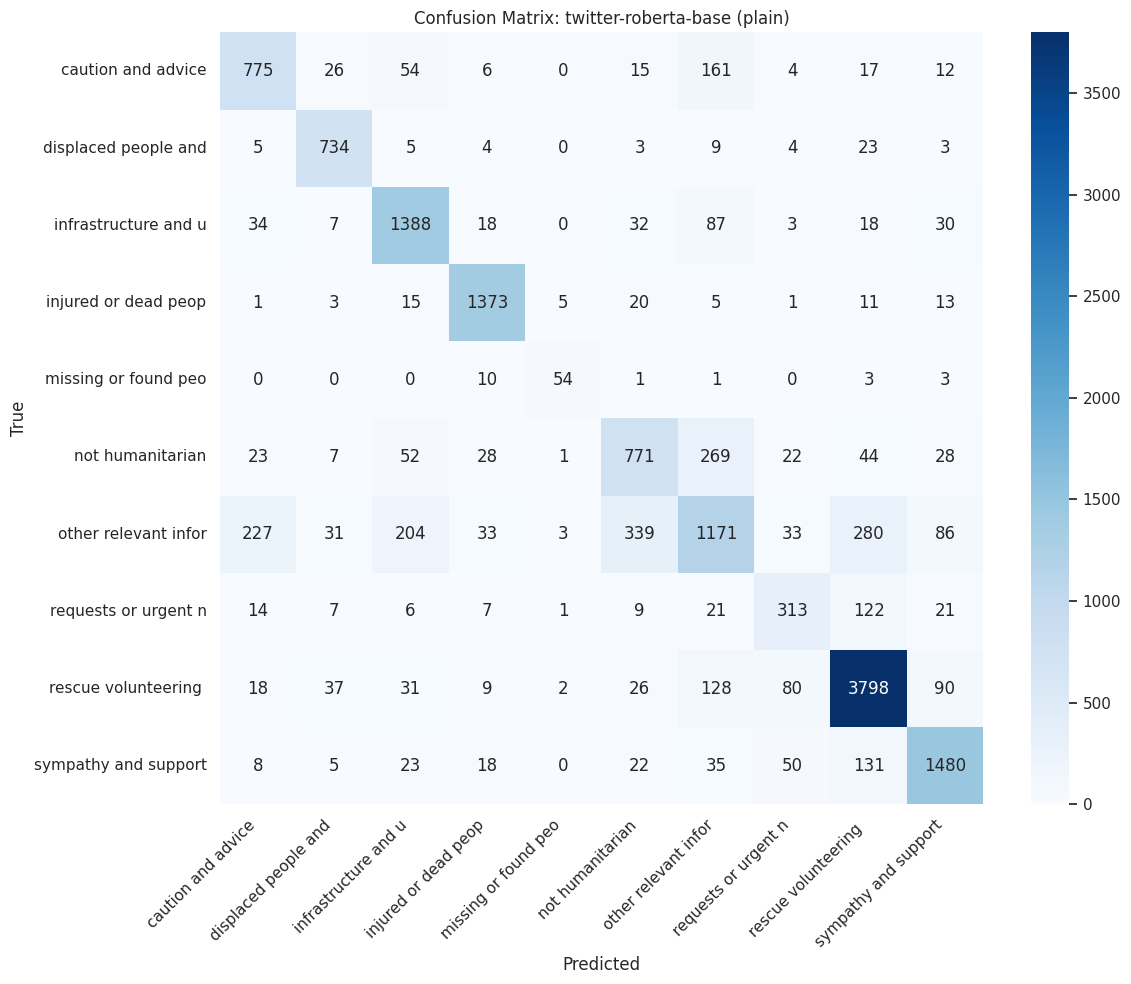

Saved                confusion_matrix.png


In [29]:
# PART 7 step 1 — generate classification_report.json and confusion_matrix.png
main_rid = best_rid
m        = all_results[main_rid]

test_logits = np.load(os.path.join(LOGITS_DIR, f"{main_rid}_test_logits.npy"))
test_labels = np.load(os.path.join(LOGITS_DIR, f"{main_rid}_test_labels.npy"))
test_preds  = np.argmax(test_logits, axis=-1)

# classification_report.json
report = clf_report(test_labels, test_preds, target_names=LABELS, output_dict=True)
report_out = {
    "macro_f1": round(report["macro avg"]["f1-score"], 4),
    "per_label": {
        lab: {
            "precision": round(report[lab]["precision"], 4),
            "recall":    round(report[lab]["recall"], 4),
            "f1":        round(report[lab]["f1-score"], 4),
            "support":   int(report[lab]["support"]),
        }
        for lab in LABELS
    },
}
with open(os.path.join(RESULTS_DIR, "classification_report.json"), "w") as f:
    json.dump(report_out, f, indent=2)
print(f"{'Saved':<20} classification_report.json")

# confusion_matrix.png
cm    = confusion_matrix(test_labels, test_preds)
short = [l.replace("_", " ")[:20] for l in LABELS]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=short, yticklabels=short, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion Matrix: {m['encoder'].split('/')[-1]} ({m['imbalance']})")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=180, bbox_inches="tight")
plt.show()
print(f"{'Saved':<20} confusion_matrix.png")

### 7.2 — Imbalance ablation and runtime

In [30]:
# PART 7 step 2 — imbalance_ablation.json and runtime.json

# imbalance_ablation.json
ablation = {}
for encoder_name, runs in [("distilbert", ["A1","A2","A3"]),
                            ("twitter-roberta", ["A4","A5","A6"])]:
    ablation[encoder_name] = {}
    for rid in runs:
        r = all_results[rid]
        ablation[encoder_name][r["imbalance"]] = {
            "macro_f1":   r["test_macro_f1"],
            "smallest_3": {sc: r["per_label"][sc] for sc in SMALLEST_3},
        }

with open(os.path.join(RESULTS_DIR, "imbalance_ablation.json"), "w") as f:
    json.dump(ablation, f, indent=2)
print(f"{'Saved':<20} imbalance_ablation.json")

# runtime.json
runtime = {
    "winner_run_id":                main_rid,
    "encoder":                      all_results[main_rid]["encoder"],
    "train_time_sec":               all_results[main_rid]["train_time_sec"],
    "inference_time_per_sample_sec": all_results[main_rid]["inference_time_per_sample_sec"],
    "all_runs": {
        rid: {
            "train_time_sec":               all_results[rid]["train_time_sec"],
            "inference_time_per_sample_sec": all_results[rid]["inference_time_per_sample_sec"],
        }
        for rid in all_results
    },
}
with open(os.path.join(RESULTS_DIR, "runtime.json"), "w") as f:
    json.dump(runtime, f, indent=2)
print(f"{'Saved':<20} runtime.json")

mark_done("artifacts")

Saved                imbalance_ablation.json
Saved                runtime.json
  >> stage 'artifacts' persisted


## 8 — Persist Outputs

### 8.1 — List saved files

In [33]:
!kaggle datasets create -p /kaggle/working/outputs -n humaid-nb1-outputs --public

usage: kaggle [-h] [-v] [-W]
              {competitions,c,datasets,d,kernels,k,models,m,files,f,benchmarks,b,config,auth}
              ...
kaggle: error: unrecognized arguments: -n humaid-nb1-outputs


In [31]:
# PART 8 step 1 — list all output files and sizes
print(f"{'File':<65} {'Size KB':>8}")
print("-" * 75)
total_kb = 0
for root, dirs, files in os.walk(OUTPUT_DIR):
    for fname in sorted(files):
        fp = os.path.join(root, fname)
        sz = os.path.getsize(fp) / 1024
        total_kb += sz
        print(f"  {os.path.relpath(fp, OUTPUT_DIR):<63} {sz:>8.1f}")
print("-" * 75)
print(f"  {'Total':<63} {total_kb:>8.1f}")

if ON_KAGGLE:
    print("\nOutputs auto-saved with notebook version.")
    print("For explicit dataset push: kaggle datasets version -m 'NB1 complete'")

File                                                               Size KB
---------------------------------------------------------------------------
  .done_artifacts                                                      0.0
  .done_data_loaded                                                    0.0
  .done_go_no_go                                                       0.0
  .done_multi_seed                                                     0.0
  .done_run_A1                                                         0.0
  .done_run_A2                                                         0.0
  .done_run_A3                                                         0.0
  .done_run_A4                                                         0.0
  .done_run_A4_s123                                                    0.0
  .done_run_A5                                                         0.0
  .done_run_A6                                                         0.0
  checkpoints/A4_best/co

## Summary

In [32]:
# PART summary — final status
print("Notebook 1 complete: Regime A Training")
print("=" * 60)
print(f"{'Winner':<25} {best_rid}")
print(f"{'Encoder':<25} {winner['encoder']}")
print(f"{'Imbalance':<25} {winner['imbalance']}")
print(f"{'Val macro-F1':<25} {winner['val_macro_f1']:.4f}")
print(f"{'Test macro-F1':<25} {winner['test_macro_f1']:.4f}")
print(f"{'Mean +/- range (2s)':<25} {mean_f1:.4f} +/- {f1_range:.4f}")
print()
print("Handoff to Notebook 2 (calibration + selective prediction):")
print(f"  Logits:     {LOGITS_DIR}/{best_rid}_*.npy")
print(f"  Checkpoint: {CKPT_DIR}/{best_rid}_best/")
print()
print("Handoff to Notebook 3 (cross-event):")
print(f"  Winner config: {RESULTS_DIR}/go_no_go_decision.json")

Notebook 1 complete: Regime A Training
Winner                    A4
Encoder                   cardiffnlp/twitter-roberta-base
Imbalance                 plain
Val macro-F1              0.7589
Test macro-F1             0.7621
Mean +/- range (2s)       0.7642 +/- 0.0043

Handoff to Notebook 2 (calibration + selective prediction):
  Logits:     /kaggle/working/outputs/logits/transformer/A4_*.npy
  Checkpoint: /kaggle/working/outputs/checkpoints/A4_best/

Handoff to Notebook 3 (cross-event):
  Winner config: /kaggle/working/outputs/results/transformer/go_no_go_decision.json
